In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn import metrics
from scipy.stats import shapiro
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

**Interpretasi:**

Cell ini cuma manggil library yang bakal dipake: `numpy` dan `pandas` buat olah data, `seaborn` dan `matplotlib` buat bikin grafik, `StandardScaler` dan `train_test_split` dari `sklearn` buat scaling dan bagi data, `shapiro` buat uji normalitas, dan `statsmodels` buat regresi OLS. Belum ada hasil yang perlu diinterpretasi.

In [2]:
path = 'data/train.csv'
df = pd.read_csv(path)
df

,id,Sex,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,0,male,36,189.0,82.0,26.0,101.0,41.0,150.0
1,1,female,64,163.0,60.0,8.0,85.0,39.7,34.0
2,2,female,51,161.0,64.0,7.0,84.0,39.8,29.0
3,3,male,20,192.0,90.0,25.0,105.0,40.7,140.0
4,4,female,38,166.0,61.0,25.0,102.0,40.6,146.0
...,...,...,...,...,...,...,...,...,...
749995,749995,male,28,193.0,97.0,30.0,114.0,40.9,230.0
749996,749996,female,64,165.0,63.0,18.0,92.0,40.5,96.0
749997,749997,male,60,162.0,67.0,29.0,113.0,40.9,221.0
749998,749998,male,45,182.0,91.0,17.0,102.0,40.3,109.0


diketahui ternyata oh ternyata dat trainnya ada 750000 baris x 9 kolom

In [3]:
df.columns


Index(['id', 'Sex', 'Age', 'Height', 'Weight', 'Duration', 'Heart_Rate',
       'Body_Temp', 'Calories'],
      dtype='str')

dan ada 9 kolom yaitu `'id'`, `'Sex'`, '`Age`', `Height` , `Weight`, `Duration`, '`Heart_Rate`', '`Body_Temp`, `Calories`

In [4]:
calories = pd.read_csv(path, usecols=['Age', 'Duration', 'Heart_Rate', 'Body_Temp', 'Calories'])

dan aku hanya memilih 4 yaitu `Duration`, `Heart_Rate`, `Body_Temp`, `Age`

In [5]:
calories.info()
calories.describe()

<class 'pandas.DataFrame'>
RangeIndex: 750000 entries, 0 to 749999
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Age         750000 non-null  int64  
 1   Duration    750000 non-null  float64
 2   Heart_Rate  750000 non-null  float64
 3   Body_Temp   750000 non-null  float64
 4   Calories    750000 non-null  float64
dtypes: float64(4), int64(1)
memory usage: 28.6 MB


,Age,Duration,Heart_Rate,Body_Temp,Calories
count,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000
mean,41.420404,15.421015,95.483995,40.036253,88.282781
std,15.175049,8.354095,9.449845,0.779875,62.395349
min,20.000000,1.000000,67.000000,37.100000,1.000000
25%,28.000000,8.000000,88.000000,39.600000,34.000000
50%,40.000000,15.000000,95.000000,40.300000,77.000000
75%,52.000000,23.000000,103.000000,40.700000,136.000000
max,79.000000,30.000000,128.000000,41.500000,314.000000


**Interpretasi:**

- Semua kolom isinya lengkap (750.000 data, nggak ada yang kosong).
- Rata-rata umur sekitar 41 tahun, durasi olahraga sekitar 15 menit, detak jantung sekitar 95, suhu badan sekitar 40°C, dan kalori yang kebakar sekitar 88.
- Rentang `Calories` lebar banget (1 sampai 314) dengan standar deviasi sekitar 62, jadi kalori yang kebakar antar orang beda-bedanya jauh.

In [6]:
display(calories.isna().sum())

duplicate = calories[calories.duplicated()]
duplicate

Age           0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64

,Age,Duration,Heart_Rate,Body_Temp,Calories
203,51,3.0,81.0,38.8,10.0
431,22,22.0,97.0,40.7,111.0
1723,48,11.0,91.0,40.2,53.0
1902,49,3.0,85.0,38.7,12.0
2179,51,3.0,81.0,38.8,10.0
...,...,...,...,...,...
749985,50,23.0,100.0,40.8,132.0
749988,33,11.0,90.0,39.6,44.0
749990,58,5.0,87.0,39.4,23.0
749998,45,17.0,102.0,40.3,109.0


**Interpretasi:**

- Missing value di semua kolom = 0, jadi nggak perlu diisi atau dibuang.
- Ada 169.270 baris yang kebaca duplikat. Ini karena kolom `id`, `Sex`, `Height`, dan `Weight` udah nggak dipake, jadi baris yang nilai 5 kolomnya kebetulan sama dianggap kembar. Jadi bukan data yang bener-bener dobel.

In [7]:

calories = calories.drop_duplicates()

**Interpretasi:**

Baris duplikat dibuang pakai `drop_duplicates()`. Hasilnya dilihat di cell berikutnya.

In [8]:
calories.shape

(580730, 5)

**Interpretasi:**

Setelah duplikat dibuang, datanya sisa 580.730 baris dan 5 kolom. Masih banyak banget, jadi aman buat bikin model.

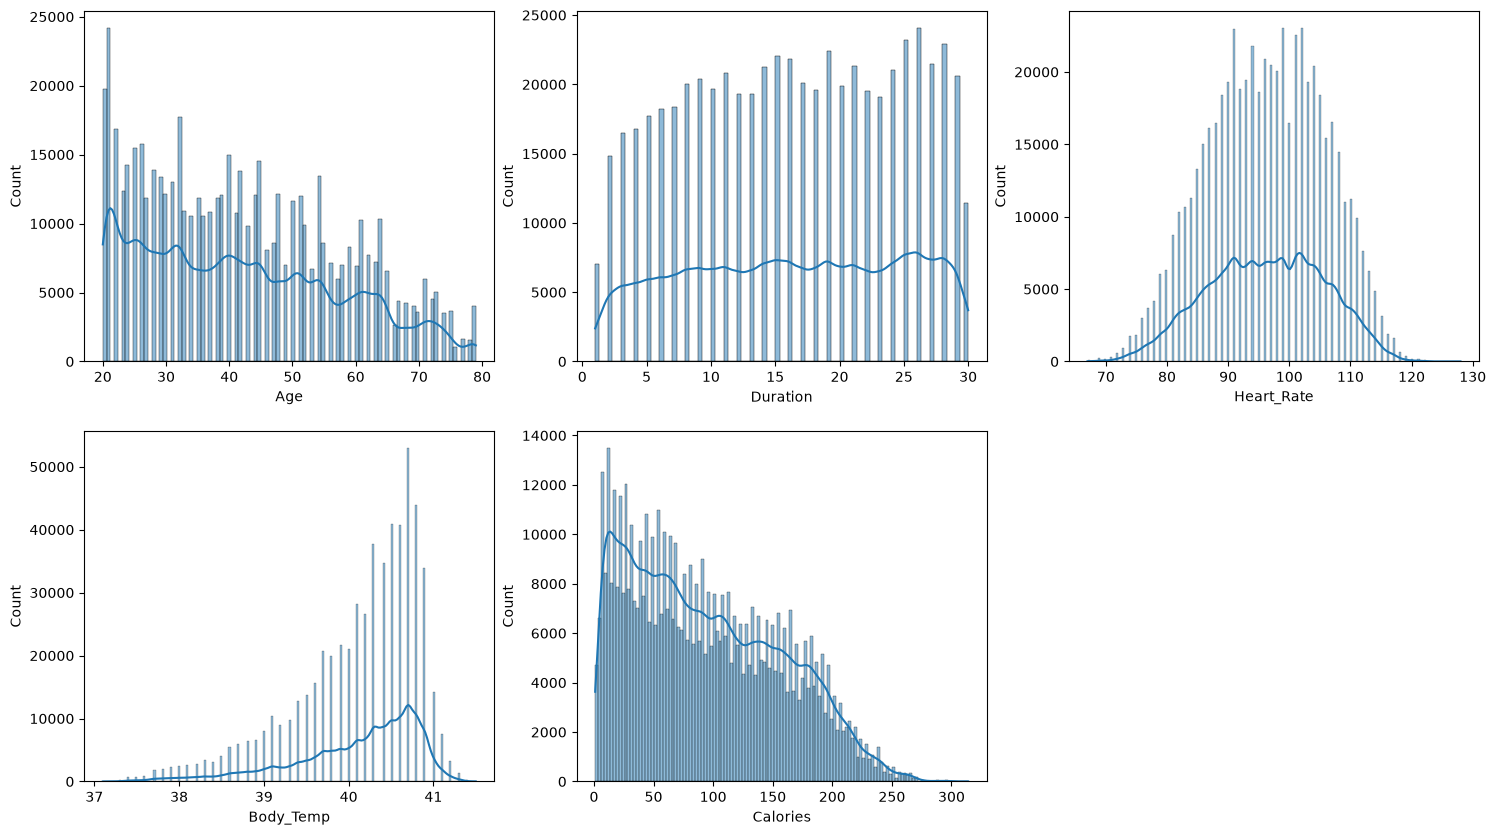

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.histplot(calories["Age"], kde=True, ax=axes[0,0])
sns.histplot(calories["Duration"], kde=True, ax=axes[0,1])
sns.histplot(calories["Heart_Rate"], kde=True, ax=axes[0,2])
sns.histplot(calories["Body_Temp"], kde=True, ax=axes[1,0])
sns.histplot(calories["Calories"], kde=True, ax=axes[1,1])
axes[1,2].axis('off')
plt.show()

**Interpretasi:**

- `Age`: miring ke kanan. Paling banyak yang umur 20-an, makin tua makin sedikit.
- `Duration`: sebarannya lumayan rata dari 1 sampai 30 menit.
- `Heart_Rate`: paling mirip bentuk lonceng, berpusat di sekitar 90-100.
- `Body_Temp`: miring ke kiri, numpuk di sekitar 40-41°C.
- `Calories`: miring ke kanan, paling banyak yang kalorinya rendah.

Intinya nggak ada variabel yang bener-bener normal.

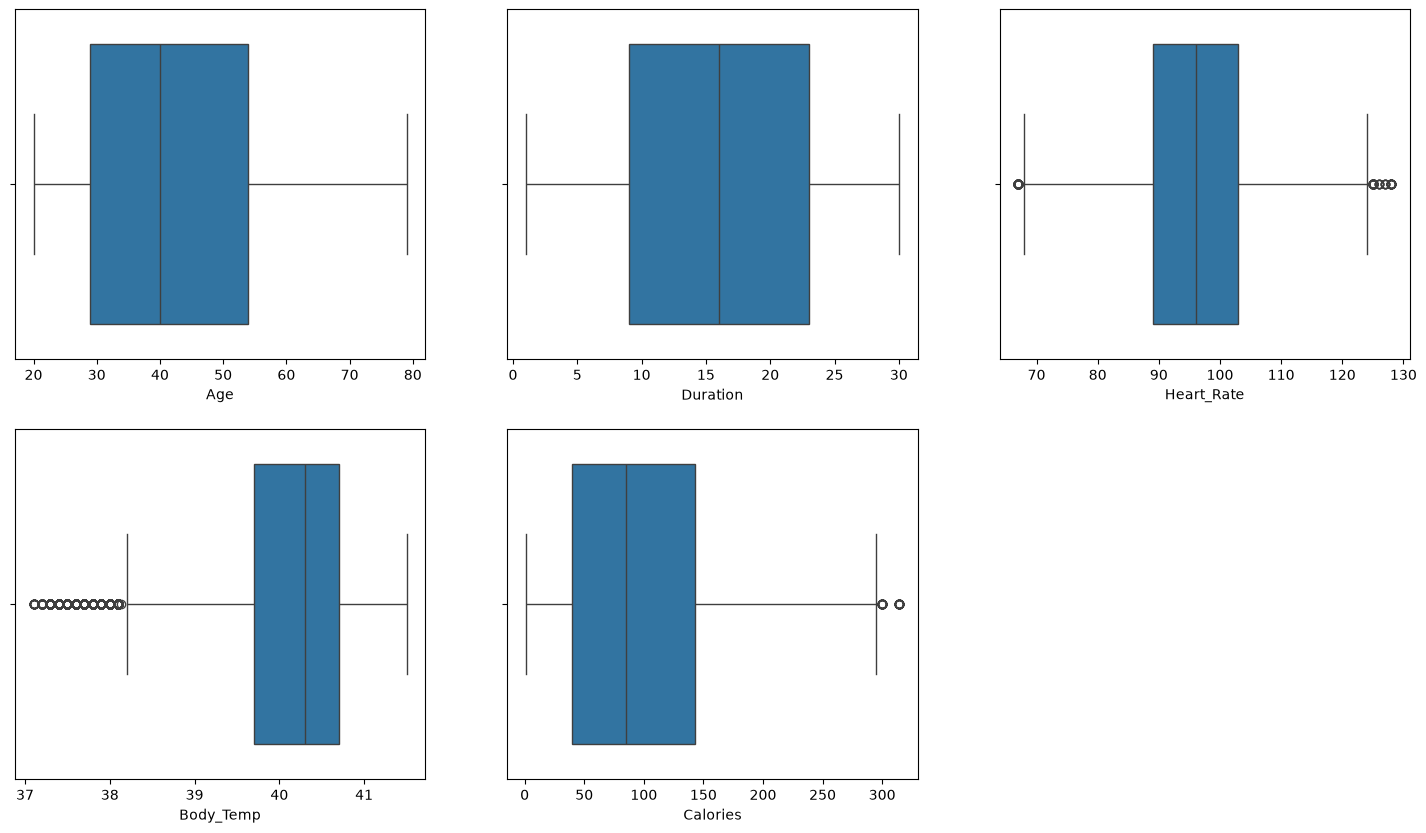

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.boxplot(x=calories['Age'], ax= axes[0,0])
sns.boxplot(x=calories['Duration'], ax= axes[0,1])
sns.boxplot(x=calories['Heart_Rate'], ax= axes[0,2])
sns.boxplot(x=calories['Body_Temp'], ax= axes[1,0])
sns.boxplot(x=calories['Calories'], ax= axes[1,1])
axes[1,2].axis('off')
plt.show()

**Interpretasi:**

- `Age` dan `Duration` bersih, nggak ada outlier.
- `Heart_Rate` punya beberapa outlier kecil di ujung bawah dan atas.
- `Body_Temp` punya banyak outlier di sisi bawah (suhu sekitar 37-38°C).
- `Calories` punya sedikit outlier di atas 300.

Outlier-nya masih masuk akal buat data olahraga, jadi nggak dibuang.

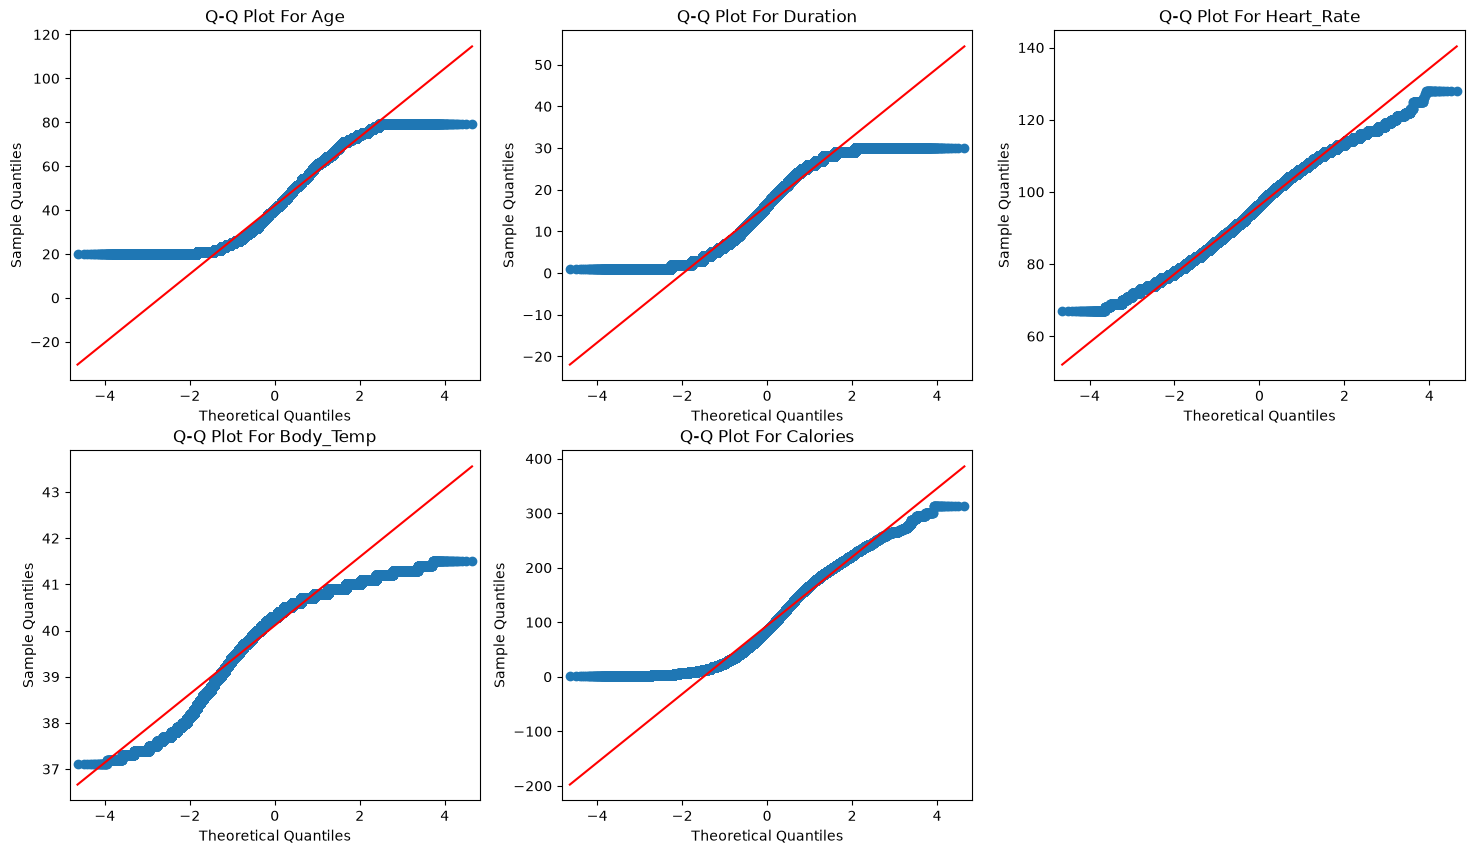

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sm.graphics.qqplot(calories['Age'].dropna(), line='s', ax=axes[0,0])
axes[0,0].title.set_text("Q-Q Plot For Age")

sm.graphics.qqplot(calories['Duration'].dropna(), line='s', ax=axes[0,1])
axes[0,1].title.set_text("Q-Q Plot For Duration")

sm.graphics.qqplot(calories['Heart_Rate'].dropna(), line='s', ax=axes[0,2])
axes[0,2].title.set_text("Q-Q Plot For Heart_Rate")

sm.graphics.qqplot(calories['Body_Temp'].dropna(), line='s', ax=axes[1,0])
axes[1,0].title.set_text("Q-Q Plot For Body_Temp")

sm.graphics.qqplot(calories['Calories'].dropna(), line='s', ax=axes[1,1])
axes[1,1].title.set_text("Q-Q Plot For Calories")

axes[1,2].axis('off')
plt.show()

**Interpretasi:**

Kalo datanya normal, titik-titik bakal nempel di garis merah. Di sini titiknya ngelengkung dan nyimpang di ujung-ujungnya, terutama `Age`, `Duration`, dan `Calories`. `Heart_Rate` paling mendingan karena paling deket ke garis. Jadi variabel-variabelnya nggak normal, sama kayak kesimpulan dari histogram.

In [12]:
sample = calories.sample(5000, random_state=0)
column = sample.columns

for i in column:
    stat, p = shapiro(sample[i])
    print("Statistics = %.3f, p=%.3f"% (stat, p))
    alpha = 0.05
    if p > alpha:
        print("Gagal tolak H_0, {} Berdistribusi Normal".format(i))
    else:
        print("Tolak H_0, {} tidak berdistribusi Normal".format(i))

Statistics = 0.950, p=0.000
Tolak H_0, Age tidak berdistribusi Normal
Statistics = 0.957, p=0.000
Tolak H_0, Duration tidak berdistribusi Normal
Statistics = 0.992, p=0.000
Tolak H_0, Heart_Rate tidak berdistribusi Normal
Statistics = 0.907, p=0.000
Tolak H_0, Body_Temp tidak berdistribusi Normal
Statistics = 0.954, p=0.000
Tolak H_0, Calories tidak berdistribusi Normal


**Interpretasi:**

Hipotesisnya: H₀ = data berdistribusi normal, H₁ = data tidak berdistribusi normal.

Semua variabel p-value = 0.000, lebih kecil dari alpha 0.05, jadi H₀ ditolak. Artinya semua variabel (`Age`, `Duration`, `Heart_Rate`, `Body_Temp`, `Calories`) nggak berdistribusi normal. Yang paling deket ke normal `Heart_Rate` (statistik 0.992), yang paling jauh `Body_Temp` (0.907).

Uji ini pakai sampel 5.000 data karena Shapiro-Wilk cuma cocok buat data segitu.

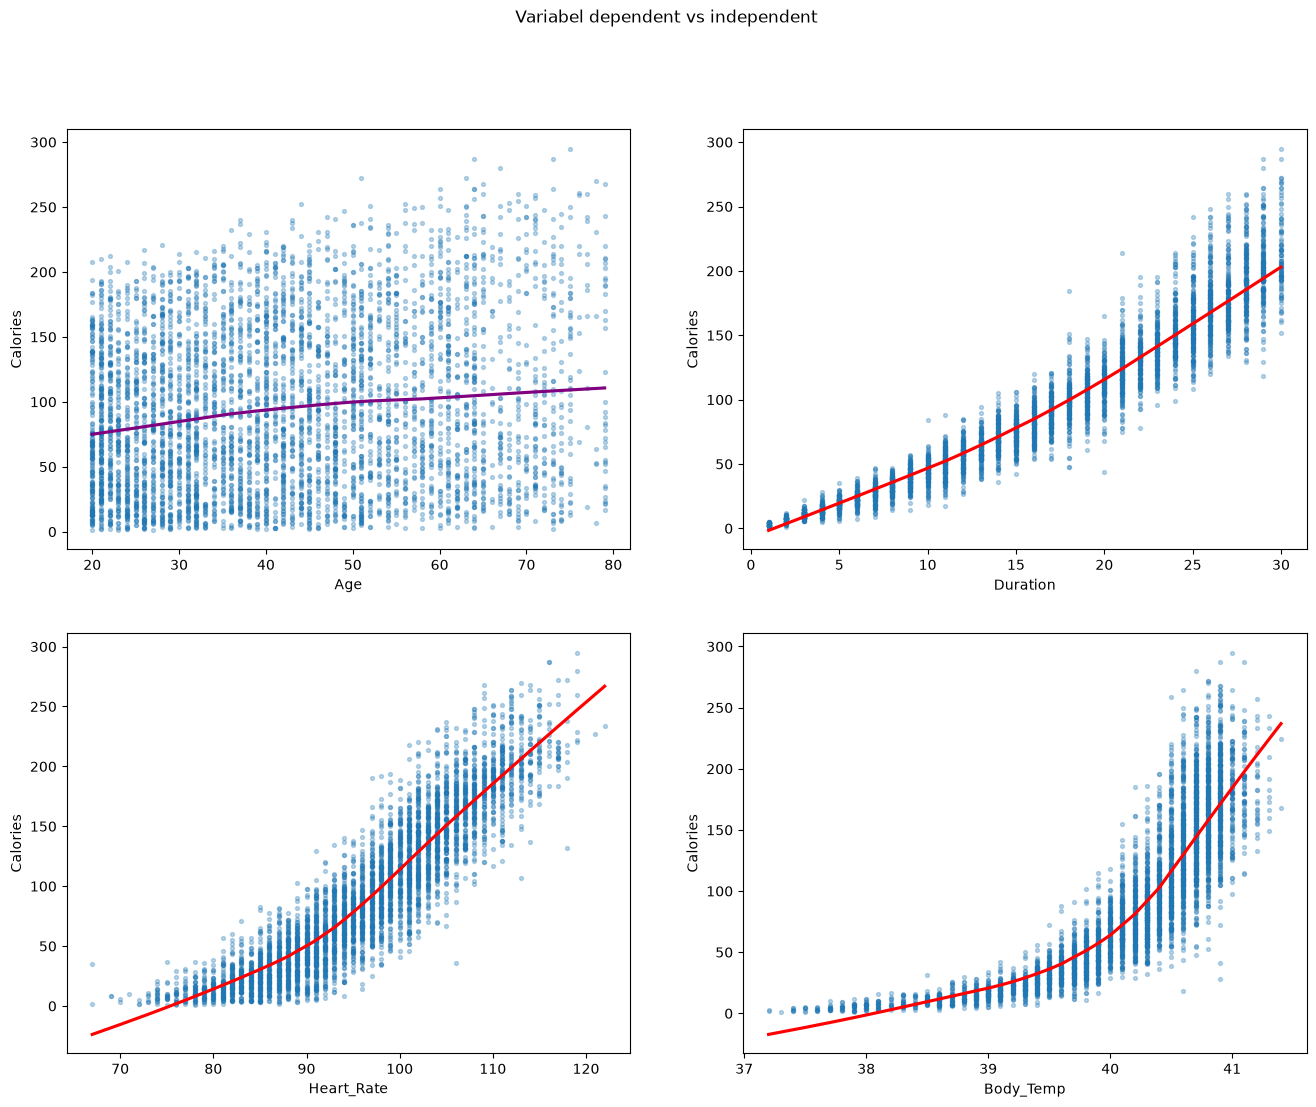

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Variabel dependent vs independent")
sns.regplot(x=sample['Age'], y=sample['Calories'], lowess=True, line_kws = {'color':'purple'}, scatter_kws={'alpha':0.3, 's':8}, ax=axes[0,0])
sns.regplot(x=sample['Duration'], y=sample['Calories'], lowess=True, line_kws = {'color':'red'}, scatter_kws={'alpha':0.3, 's':8}, ax=axes[0,1])
sns.regplot(x=sample['Heart_Rate'], y=sample['Calories'], lowess=True, line_kws = {'color':'red'}, scatter_kws={'alpha':0.3, 's':8}, ax=axes[1,0])
sns.regplot(x=sample['Body_Temp'], y=sample['Calories'], lowess=True, line_kws = {'color':'red'}, scatter_kws={'alpha':0.3, 's':8}, ax=axes[1,1])
plt.show()

**Interpretasi:**

- `Age` vs `Calories`: garisnya naik tipis banget, hubungannya lemah.
- `Duration` vs `Calories`: naik jelas dan hampir lurus. Makin lama olahraga, makin banyak kalori kebakar.
- `Heart_Rate` vs `Calories`: naik kuat, sedikit melengkung ke atas.
- `Body_Temp` vs `Calories`: kalo suhu di bawah 39 kalorinya hampir datar, abis 40 naik tajam, jadi agak melengkung.

Titik-titiknya juga makin melebar di kalori tinggi, jadi sebarannya nggak seragam.

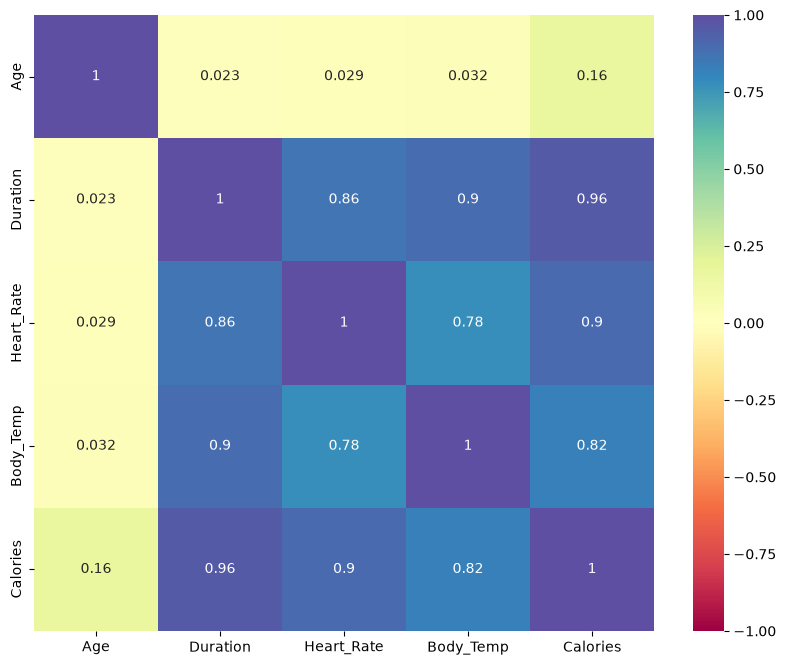

In [14]:
plt.figure(figsize=(10,8))
sns.heatmap(calories.corr(), vmax=1, vmin=-1, center = 0 ,\
    cmap="Spectral", annot=True)
plt.show()

**Interpretasi:**

Korelasi sama `Calories`:
- `Duration` = 0.96 (paling kuat)
- `Heart_Rate` = 0.90
- `Body_Temp` = 0.82
- `Age` = 0.16 (lemah)

Variabel X-nya juga saling berkorelasi tinggi: `Duration`-`Body_Temp` 0.90, `Duration`-`Heart_Rate` 0.86, `Heart_Rate`-`Body_Temp` 0.78. Ini tanda awal ada **multikolinearitas**, bakal dibahas lagi di model 2.

In [15]:
scaler = StandardScaler()
scaled_calories = scaler.fit_transform(calories)
scaled_calories

array([[-0.39045466,  1.1903563 ,  0.50267763,  1.20046832,  0.89113708],
       [ 1.4032611 , -0.99894179, -1.18181765, -0.55098197, -0.95500283],
       [ 0.5704645 , -1.12056946, -1.2870986 , -0.41625503, -1.03457783],
       ...,
       [-0.90294488,  1.67686699,  1.87133004,  1.06574138,  2.16433701],
       [ 1.4032611 ,  0.21733493, -0.44485097,  0.52683359,  0.03172712],
       [ 1.14701599,  1.55523932,  1.76604909,  1.06574138,  2.02110202]],
      shape=(580730, 5))

**Interpretasi:**

Semua kolom diubah ke skala standar (rata-rata 0, standar deviasi 1) pakai `StandardScaler`, biar nggak ada variabel yang "menang" cuma karena angkanya gede. Hasilnya masih berupa array angka.

In [16]:
scaled_calories = pd.DataFrame(scaled_calories, columns=calories.columns)
scaled_calories

,Age,Duration,Heart_Rate,Body_Temp,Calories
0,-0.390455,1.190356,0.502678,1.200468,0.891137
1,1.403261,-0.998942,-1.181818,-0.550982,-0.955003
2,0.570464,-1.120569,-1.287099,-0.416255,-1.034578
3,-1.415435,1.068729,0.923801,0.796287,0.731987
4,-0.262332,1.068729,0.607959,0.661561,0.827477
...,...,...,...,...,...
580725,-1.095129,-0.390803,0.502678,-0.012074,-0.445723
580726,-1.351374,-0.634059,-1.076537,-0.820436,-0.827683
580727,-0.902945,1.676867,1.871330,1.065741,2.164337
580728,1.403261,0.217335,-0.444851,0.526834,0.031727


**Interpretasi:**

Hasil scaling dibalikin jadi tabel biar nama kolomnya ada lagi. Sekarang nilainya ada yang minus, itu wajar karena artinya nilai tersebut di bawah rata-rata.

## BUAT MODEL

In [17]:
x = scaled_calories.drop("Calories", axis=1).values
y = scaled_calories['Calories'].values.reshape(-1,1)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)

**Interpretasi:**

`Calories` dijadiin y, sisanya (`Age`, `Duration`, `Heart_Rate`, `Body_Temp`) jadi X. Data dibagi 70% buat latih model dan 30% buat uji, pakai `random_state=0` biar hasil pembagiannya selalu sama.

In [18]:
print("Ukuran X train", len(x_train))
print("Ukuran X tes", len(x_test))
print("Ukuran y train", len(y_train))
print("Ukuran y tes", len(y_test))

Ukuran X train 406511
Ukuran X tes 174219
Ukuran y train 406511
Ukuran y tes 174219


**Interpretasi:**

Data latih ada 406.511 baris dan data uji 174.219 baris. Jumlah X dan y-nya sama, jadi pembagiannya udah bener.

$$Y=\beta_0+\beta_1X_1+\beta_2X_2+\beta_3X_3+\beta_4X_4+\epsilon$$

dengan $Y$ = `Calories`, $X_1$ = `Age`, $X_2$ = `Duration`, $X_3$ = `Heart_Rate`, $X_4$ = `Body_Temp` (semuanya sudah di-*scaling*).

**Interpretasi:**

Ini persamaan regresi linear berganda. β₀ itu intercept, β₁ sampai β₄ itu pengaruh tiap variabel ke kalori, dan ε itu error (selisih tebakan model sama data asli).

In [19]:
input = sm.add_constant(x_train)

**Interpretasi:**

`add_constant` nambahin kolom isi angka 1 biar `statsmodels` ikut ngitung intercept (β₀). Kalo nggak ditambah, model dipaksa lewat titik 0.

In [20]:
SimpleModel = sm.OLS(y_train, input, missing = 'drop')
results = SimpleModel.fit()

**Interpretasi:**

Model OLS dilatih pakai data latih. Belum ada output, hasilnya ditampilin di cell berikutnya.

In [21]:
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.965
Model:                            OLS   Adj. R-squared:                  0.965
Method:                 Least Squares   F-statistic:                 2.792e+06
Date:                Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:44:47   Log-Likelihood:             1.0387e+05
No. Observations:              406511   AIC:                        -2.077e+05
Df Residuals:                  406506   BIC:                        -2.077e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       4.719e-05      0.000      0.161      0.8

**Interpretasi:**

- **R-squared = 0.965:** 96,5% variasi kalori bisa dijelasin sama 4 variabel ini. Bagus banget.
- **Uji F:** Prob (F-statistic) = 0.00, lebih kecil dari 0.05, jadi minimal ada satu variabel yang berpengaruh. Modelnya layak dipake.
- **Uji t:** Semua variabel p-value = 0.000, jadi semuanya signifikan. Konstanta nggak signifikan (p = 0.872), wajar karena data udah di-scaling jadi rata-ratanya 0.
- **Koefisien (satuan standar deviasi):**
  - x1 (`Age`) = 0.142
  - x2 (`Duration`) = 0.873, pengaruh paling gede
  - x3 (`Heart_Rate`) = 0.305
  - x4 (`Body_Temp`) = -0.204, negatif. Padahal di korelasi hubungannya positif, kemungkinan karena multikolinearitas.
- **Durbin-Watson = 2.003:** Deket 2, jadi nggak ada autokorelasi.
- **Skew 1.083 dan Kurtosis 7.362:** Residualnya agak miring dan ekornya tebal, jadi kemungkinan residual nggak normal.

In [22]:
input_test = sm.add_constant(x_test)
predication_1 = results.predict(input_test)

list_columns = []
for i in calories.columns:
    if i !="Calories":
        list_columns.append(i)
list_columns

df_statmod = pd.DataFrame(x_test, columns=list_columns)
df_statmod['actual_calories'] = y_test
df_statmod["prediction_calories"] = predication_1
df_statmod.head()

,Age,Duration,Heart_Rate,Body_Temp,actual_calories,prediction_calories
0,-0.774822,1.190356,1.029082,1.065741,1.129862,1.025274
1,-0.326393,0.095707,0.292116,0.796287,-0.095593,-0.036463
2,1.659506,-1.363825,-0.971256,-1.763524,-1.145983,-0.890324
3,-0.774822,0.217335,-0.550132,0.257380,-0.302488,-0.141156
4,0.186097,-0.877314,-0.655413,0.122653,-0.859513,-0.964562


**Interpretasi:**

Model dipake nebak kalori buat data uji, terus dibandingin sama kalori aslinya. Dari 5 baris pertama, tebakannya deket sama nilai aslinya. Contohnya baris pertama aslinya 1.13, tebakannya 1.03.

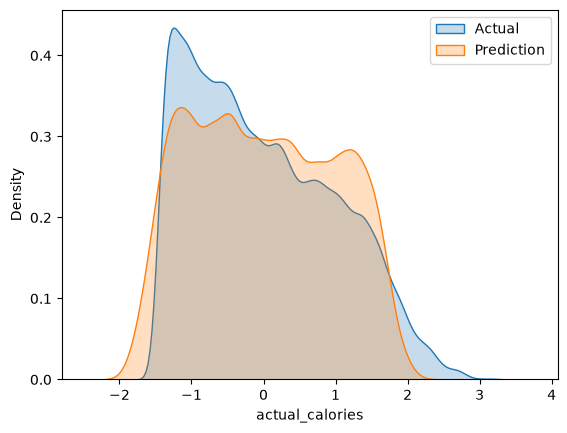

In [23]:
sns.kdeplot(df_statmod['actual_calories'], label='Actual', fill = True)
sns.kdeplot(df_statmod['prediction_calories'], label='Prediction', fill=True)

plt.legend()
plt.show()

**Interpretasi:**

Dua kurva (aktual dan prediksi) lumayan numpuk, jadi tebakan model mirip pola data aslinya. Bedanya, kurva aktual puncaknya lebih tinggi di kalori rendah, dan model agak kurang pas di situ. Model juga sempat nebak nilai di bawah batas data asli (di sekitar -2).

$$MSE\ (Mean\ Square\ Error) = \frac{1}{n}\sum_i(y_i -\hat{y}_i)^2$$

$$MAE\ (Mean\ Absolute\ Error) = \frac{1}{n}\sum_i |y_i-\hat{y}_i|$$

$$RMSE = \sqrt{MSE}$$

**Interpretasi:**

Tiga rumus ini ukuran seberapa jauh tebakan model dari data aslinya. MSE rata-rata kuadrat selisihnya, MAE rata-rata selisih mutlaknya, dan RMSE akar dari MSE. Makin kecil nilainya, makin bagus modelnya.

In [24]:

print("R-Square: ", metrics.r2_score(df_statmod['actual_calories'],
                                     df_statmod['prediction_calories']))

R-Square:  0.9650473015740908


**Interpretasi:**

R² data uji = 0.965, sama kayak data latih. Jadi modelnya nggak overfitting dan tetep bagus waktu dipake ke data baru.

In [25]:

print("MAE: ", metrics.mean_absolute_error(df_statmod['actual_calories'],
                                     df_statmod['prediction_calories']))

MAE:  0.13736701151349023


**Interpretasi:**

MAE = 0.137. Rata-rata selisih tebakan dan data asli (dalam satuan standar) kecil, jadi tebakan modelnya deket.

In [26]:

print("MSE: ", metrics.mean_squared_error(df_statmod['actual_calories'],
                                     df_statmod['prediction_calories']))

MSE:  0.03495068049920799


**Interpretasi:**

MSE = 0.035. Kecil juga, tandanya error modelnya rendah.

In [27]:

print("RMSE: ", np.sqrt(metrics.mean_squared_error(df_statmod['actual_calories'],
                                     df_statmod['prediction_calories'])))

RMSE:  0.1869510109606471


**Interpretasi:**

RMSE = 0.187. Kalo dibalikin ke satuan asli kira-kira belasan kalori (perkiraan, dikali standar deviasi `Calories` yang sekitar 60-an). Dibanding rentang kalori yang sampe 300, error segitu masih kecil.

In [28]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv('data/train.csv')
print("Shape Train:", train_df.shape)
train_df.head()

Shape Train: (750000, 9)


,id,Sex,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,0,male,36,189.0,82.0,26.0,101.0,41.0,150.0
1,1,female,64,163.0,60.0,8.0,85.0,39.7,34.0
2,2,female,51,161.0,64.0,7.0,84.0,39.8,29.0
3,3,male,20,192.0,90.0,25.0,105.0,40.7,140.0
4,4,female,38,166.0,61.0,25.0,102.0,40.6,146.0


**Interpretasi:**

Mulai di sini dibuat model kedua pakai data asli tanpa scaling. Datanya dibaca ulang, hasilnya 750.000 baris dan 9 kolom, sama kayak data awal.

In [29]:

print(train_df.info())


<class 'pandas.DataFrame'>
RangeIndex: 750000 entries, 0 to 749999
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   id          750000 non-null  int64  
 1   Sex         750000 non-null  str    
 2   Age         750000 non-null  int64  
 3   Height      750000 non-null  float64
 4   Weight      750000 non-null  float64
 5   Duration    750000 non-null  float64
 6   Heart_Rate  750000 non-null  float64
 7   Body_Temp   750000 non-null  float64
 8   Calories    750000 non-null  float64
dtypes: float64(6), int64(2), str(1)
memory usage: 51.5 MB
None


**Interpretasi:**

Semua kolom udah keisi lengkap (750.000 data) dan tipe datanya sesuai: angka buat `Age`, `Duration`, `Heart_Rate`, `Body_Temp`, `Calories`, dan teks buat `Sex`.

In [30]:
print(train_df.isnull().sum())

id            0
Sex           0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64


**Interpretasi:**

Missing value di semua kolom = 0, jadi nggak ada data yang perlu diisi atau dibuang.

In [31]:
# Hapus duplikat jika ada
train_df = train_df.drop_duplicates()
print("\nJumlah baris setelah drop_duplicates:", len(train_df))


Jumlah baris setelah drop_duplicates: 750000


**Interpretasi:**

Jumlah baris setelah `drop_duplicates` tetep 750.000, jadi nggak ada duplikat. Ini beda sama model 1 karena sekarang kolom `id` ikut kebawa, dan `id` unik di tiap baris. Jadi data model 1 (580.730 baris) dan model 2 (750.000 baris) nggak persis sama.

In [32]:
# Menentukan Variabel Independen (X) dan Dependen (y)
features = ['Age', 'Duration', 'Heart_Rate', 'Body_Temp']
X = train_df[features]
y = train_df['Calories']


**Interpretasi:**

Variabel X dipilih: `Age`, `Duration`, `Heart_Rate`, `Body_Temp`. Variabel y: `Calories`. Sama kayak model 1, bedanya sekarang nilainya masih asli (belum di-scaling).

In [33]:
# Menambahkan konstanta (intercept) wajib untuk statsmodels
X_const = sm.add_constant(X)

**Interpretasi:**

Konstanta ditambah biar model ngitung intercept, sama kayak di model 1.

In [34]:
# Fitting Model Regresi Linear (OLS)
model = sm.OLS(y, X_const)
results = model.fit()

**Interpretasi:**

Model OLS dilatih pakai seluruh data (750.000 baris). Hasilnya ditampilin di cell berikutnya.

In [35]:
# Menampilkan Ringkasan Hasil (Uji t dan Uji F)
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:               Calories   R-squared:                       0.968
Model:                            OLS   Adj. R-squared:                  0.968
Method:                 Least Squares   F-statistic:                 5.645e+06
Date:                Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:44:49   Log-Likelihood:            -2.8753e+06
No. Observations:              750000   AIC:                         5.751e+06
Df Residuals:                  749995   BIC:                         5.751e+06
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        503.3147      1.506    334.191      0.0

**Interpretasi:**

- **R-squared = 0.968:** Sedikit lebih tinggi dari model 1, jadi 96,8% variasi kalori bisa dijelasin variabel X.
- **Uji F:** Prob (F-statistic) = 0.00, jadi modelnya layak secara keseluruhan.
- **Uji t:** Semua variabel p-value = 0.000, jadi semuanya signifikan.
- **Koefisien (satuan asli):**
  - `Age` = 0.548: tiap nambah 1 tahun, kalori naik sekitar 0,55.
  - `Duration` = 6.750: tiap nambah 1 menit olahraga, kalori naik sekitar 6,75.
  - `Heart_Rate` = 1.958: tiap nambah 1 bpm detak jantung, kalori naik sekitar 1,96.
  - `Body_Temp` = -18.203: tiap suhu badan naik 1°C, kalori turun sekitar 18,2 (negatif lagi, kemungkinan karena multikolinearitas).
  - Konstanta = 503.3, nggak ada arti praktisnya karena suhu badan 0°C nggak mungkin.
- **Durbin-Watson = 2.003:** Nggak ada autokorelasi.
- **Cond. No. = 1.32e+04:** Ada peringatan kemungkinan multikolinearitas, nyambung sama heatmap berikutnya.

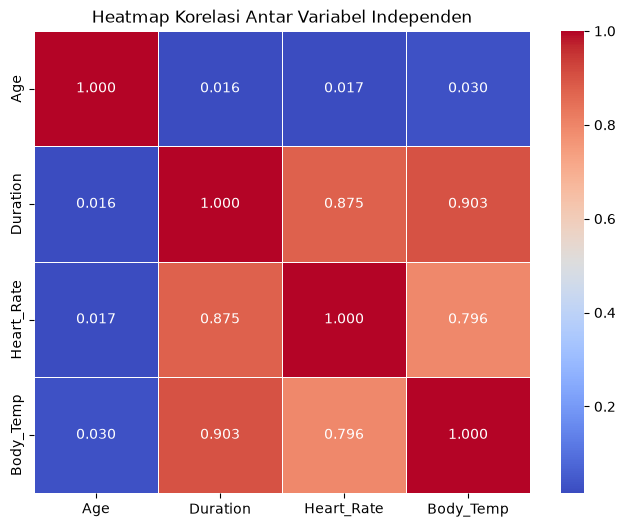

      Feature       VIF
0         Age  1.001694
1    Duration  8.507305
2  Heart_Rate  4.280258
3   Body_Temp  5.432279


In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Matriks Korelasi untuk Heatmap
corr_matrix = X.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5)
plt.title('Heatmap Korelasi Antar Variabel Independen')
plt.show()

# Perhitungan VIF (Variance Inflation Factor)
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X_const.values, i+1) for i in range(len(X.columns))]
print(vif_data)

**Interpretasi:**

- **Heatmap:** `Duration`-`Body_Temp` = 0.903, `Duration`-`Heart_Rate` = 0.875, `Heart_Rate`-`Body_Temp` = 0.796. `Age` hampir nggak berkorelasi sama variabel lain.
- **VIF:** `Age` = 1.00, `Duration` = 8.51, `Heart_Rate` = 4.28, `Body_Temp` = 5.43.

Batas umum VIF itu 10, jadi nggak ada yang lewat. Tapi `Duration` udah mendekati batas, dan `Body_Temp` serta `Heart_Rate` lumayan tinggi. Kesimpulannya multikolinearitas ada tapi masih bisa ditoleransi. Ini kemungkinan yang bikin koefisien `Body_Temp` jadi negatif.

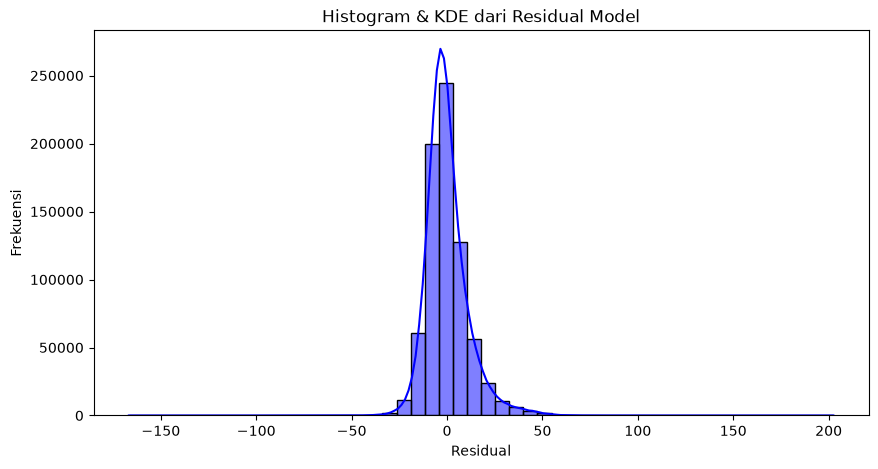

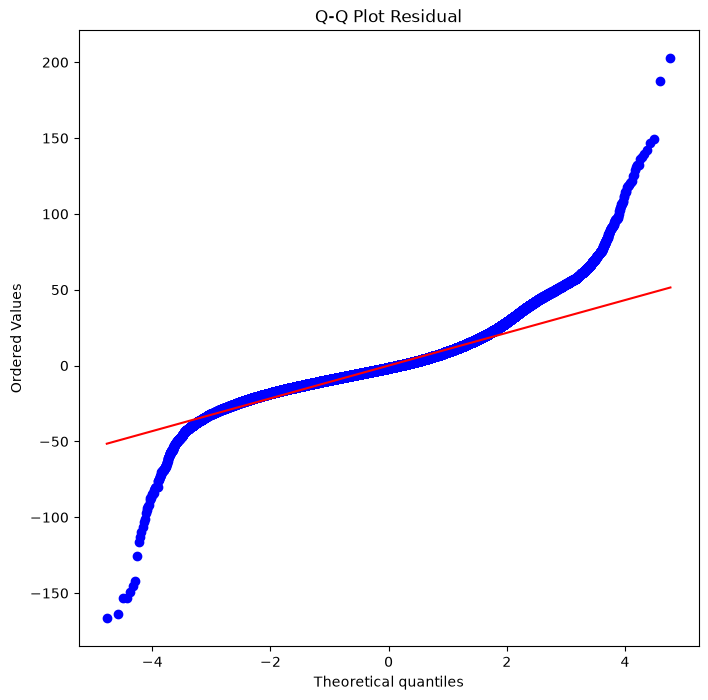

Shapiro-Wilk Statistic: 0.9164
P-value: 3.0782402525990954e-46
Kesimpulan: Residual tidak berdistribusi normal secara statistik (biasanya wajar pada sampel berukuran sangat besar).


In [37]:
from scipy import stats

# Mengambil nilai residual dari model OLS
residuals = results.resid

# 1. Visualisasi Histogram & KDE Residual
plt.figure(figsize=(10, 5))
sns.histplot(residuals, kde=True, bins=50, color='blue')
plt.title('Histogram & KDE dari Residual Model')
plt.xlabel('Residual')
plt.ylabel('Frekuensi')
plt.show()

# 2. Q-Q Plot Residual
plt.figure(figsize=(8, 8))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Q-Q Plot Residual')
plt.show()

# 3. Shapiro-Wilk Test
# Karena dataset sangat besar (750k baris), kita ambil sampel acak (misal 5000 data) karena batas maksimum scipy.stats.shapiro adalah 5000
residuals_sample = residuals.sample(n=5000, random_state=42) if len(residuals) > 5000 else residuals
shapiro_stat, shapiro_p = stats.shapiro(residuals_sample)

print(f"Shapiro-Wilk Statistic: {shapiro_stat:.4f}")
print(f"P-value: {shapiro_p}")
if shapiro_p > 0.05:
    print("Kesimpulan: Residual berdistribusi normal ( gagal tolak H0 )")
else:
    print("Kesimpulan: Residual tidak berdistribusi normal secara statistik (biasanya wajar pada sampel berukuran sangat besar).")

**Interpretasi:**

Hipotesisnya: H₀ = residual berdistribusi normal, H₁ = residual tidak berdistribusi normal.

- **Histogram:** Residual numpuk di sekitar 0 dengan puncak lancip, tapi ekornya panjang ke kanan.
- **Q-Q plot:** Titik-titiknya ngelengkung bentuk "S" dan nyimpang jauh di kedua ujung, jadi nggak normal.
- **Shapiro-Wilk:** p-value jauh di bawah 0.05, jadi H₀ ditolak. Residual nggak berdistribusi normal. Skewness 1.148 (miring ke kanan) dan kurtosis 7.855 (ekor tebal) mendukung hal ini.

Karena datanya ratusan ribu, uji normalitas gampang nolak walau penyimpangannya sebenernya kecil. Jadi pelanggaran asumsi ini masih bisa dimaklumi, tapi tetep perlu dicatat.

## Kesimpulan

Model regresi linear berganda ini bagus buat nebak kalori yang kebakar (R² sekitar 0.97), dan semua variabel (`Age`, `Duration`, `Heart_Rate`, `Body_Temp`) berpengaruh signifikan. `Duration` pengaruhnya paling besar. Kekurangannya: residual nggak berdistribusi normal, dan ada multikolinearitas antara `Duration`, `Heart_Rate`, dan `Body_Temp` (VIF masih di bawah 10 tapi lumayan tinggi).